# KOSMOS 설계 v2 — 개수 텐서로 지표 한 번에 계산

모델 원응답을 **개수 텐서** `C[m, p, i, k]`(모델 × 페르소나 × 문항 × 선지)로 모은 뒤, 모든 지표를 브로드캐스팅으로 계산한다.

| 축 | 크기 | 내용 |
|---|---|---|
| `m` | 모델 수 | deepseek, haiku, exaone … |
| `p` | 12 | `c0`, `L0`, L1 10셀 |
| `i` | 197 (test 제외) / 246 | 문항 |
| `k` | 7 | 선지. 보기 수가 적은 문항은 0으로 채우고 `MASK[i, k]`로 가린다 |

사람 정답지도 같은 모양 `H[p, i, k]`로 둔다(c0·L0 = 모집단 가중 분포, L1 = 셀 가중 분포).

- 평활화 → 확률: `(C + α·MASK)^(1/T) · MASK`를 `k`축으로 정규화. T 그리드는 앞에 축 하나를 더 붙여 한 번에 계산한다.
- **test 49문항은 기본으로 텐서에 넣지 않는다**(`INCLUDE_TEST = False`, DESIGN.md 6장).
- 쌍별 순위 일치율의 동점 처리 규칙이 아직 미정이라 규칙 A(사람 평균이 다른 모든 쌍)와 B(사람 차이 > 2SE)를 함께 낸다.

실행: KOSMOS 루트에서 `uv run --no-project --with jupyterlab --with pandas --with pyarrow --with matplotlib jupyter lab`

In [1]:
import json, itertools
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "inventory/kgss_clean.parquet").exists():
    ROOT = ROOT.parent
DESIGN = ROOT / "research/design_v2_20261112"
OUT = DESIGN / "analysis/out_nb"; OUT.mkdir(parents=True, exist_ok=True)

# 모델별 원응답 jsonl (여러 파일이면 리스트). EXAONE은 팀원 병합본이 나오면 그 파일로 바꾼다.
MODELS = {
    "deepseek": [ROOT / "raw/v2/deepseek_ultrafast_p1.jsonl"],
    "haiku":    [ROOT / "raw/v2/haiku_p1.jsonl"],
    "exaone":   [DESIGN / "team_packages/KOSMOS_EXAONE_m1_태우/exaone_m1_p1.jsonl"],
}
COMMON_K = None        # 정수로 두면 모든 모델에서 sample_idx < COMMON_K만 쓴다(공정 비교용)
INCLUDE_TEST = False   # test 분할은 최종 보고 때 한 번만
ALPHA = 0.5            # Jeffreys 평활화 (고정)
T_GRID = np.round(np.arange(0.5, 6.0001, 0.05), 2)
LAM_GRID = np.round(np.arange(0, 1.0001, 0.02), 2)
B_BOOT = 5000
rng = np.random.default_rng(20261112)
pd.set_option("display.precision", 3)
plt.rcParams["font.family"] = "AppleGothic"; plt.rcParams["axes.unicode_minus"] = False

## 1. 축 정의: 문항 · 선지 · 페르소나

In [2]:
man = pd.read_csv(DESIGN / "item_manifest_v2.csv", encoding="utf-8-sig")
if not INCLUDE_TEST:
    man = man[man.split_60_20_20 != "test"]
man = man.reset_index(drop=True)
man["codes_l"] = man["codes"].apply(json.loads)
ITEMS = man["var"].tolist()
I = len(ITEMS); K = int(man["codes_l"].apply(len).max())

CODES = np.full((I, K), np.nan)
for i, cs in enumerate(man.codes_l):
    CODES[i, :len(cs)] = cs
MASK = ~np.isnan(CODES)                  # [i, k]
CODES0 = np.nan_to_num(CODES)            # 평균 계산용 (가려진 칸 0)
NOPT = MASK.sum(1)                       # [i]
CODE2K = [{c: k for k, c in enumerate(cs)} for cs in man.codes_l]

cells = pd.read_csv(DESIGN / "cells.csv", encoding="utf-8-sig").query("level == 'L1'").reset_index(drop=True)
PERSONAS = ["c0", "L0"] + cells.cell_id.tolist()
P = len(PERSONAS); PIDX = {p: j for j, p in enumerate(PERSONAS)}
L1 = slice(2, P)                          # L1 셀 축 위치
POP_SHARE = (cells.pop_share / cells.pop_share.sum()).to_numpy()   # [10]

SPLIT = man.split_60_20_20.to_numpy()
ORD = man.scale_type.isin(["ordinal_monotone", "binary"]).to_numpy()  # 평균으로 순위 비교할 문항
print(f"문항 {I}개 (분할 {pd.Series(SPLIT).value_counts().to_dict()}), 선지 최대 {K}, 페르소나 {P}")

문항 197개 (분할 {'calibration': 148, 'validation': 49}), 선지 최대 7, 페르소나 12


## 2. 사람 정답지 텐서 `H[p, i, k]`, 평균 `HMEAN[p, i]`, 표준오차 `HSE[p, i]` (FINALWT 가중)

In [3]:
kg = pd.read_parquet(ROOT / "inventory/kgss_clean.parquet")
kg = kg[kg.YEAR == 2023].copy()
kg["band"] = pd.cut(kg.AGE, [18, 30, 40, 50, 60, 200], right=False,
                    labels=["18-29", "30-39", "40-49", "50-59", "60+"]).astype(str)
SEXCODE = {"남자": 1.0, "여자": 2.0}
groups = {"c0": kg, "L0": kg}
for _, c in cells.iterrows():
    groups[c.cell_id] = kg[(kg.SEX == SEXCODE[c.sex]) & (kg.band == c.age_band)]

H = np.zeros((P, I, K)); HMEAN = np.zeros((P, I)); HSE = np.zeros((P, I))
for p, g in groups.items():
    w_all = g["FINALWT"].to_numpy()
    for i, v in enumerate(ITEMS):
        x = g[v].to_numpy()
        ok = np.isin(x, CODES[i, MASK[i]]) & (w_all > 0)
        x, w = x[ok], w_all[ok]
        onehot = (x[:, None] == CODES[i][None, :])          # [n, k]
        H[PIDX[p], i] = (w[:, None] * onehot).sum(0) / w.sum()
        m = (w * x).sum() / w.sum()
        neff = w.sum() ** 2 / (w ** 2).sum()
        HMEAN[PIDX[p], i] = m
        HSE[PIDX[p], i] = np.sqrt((w * (x - m) ** 2).sum() / w.sum() / neff)
assert np.allclose(H.sum(-1), 1) and not H[:, ~MASK].any()
print("H", H.shape)

H (12, 197, 7)


## 3. 모델 개수 텐서 `C[m, p, i, k]`

In [4]:
def load_counts(paths, k_cap=None):
    C = np.zeros((P, I, K), dtype=np.int32)
    NINV = np.zeros((P, I), dtype=np.int32); NREF = np.zeros((P, I), dtype=np.int32)
    seen = set(); ivar = {v: i for i, v in enumerate(ITEMS)}
    for path in paths:
        for line in open(path, encoding="utf-8"):
            if not line.strip():
                continue
            r = json.loads(line)
            if r.get("invalid_type") == "api_error" or r["var"] not in ivar:
                continue
            if k_cap is not None and r["sample_idx"] >= k_cap:
                continue
            key = (r["probe_id"], r["sample_idx"])
            if key in seen:
                continue
            seen.add(key)
            p, i = PIDX[r["cell_id"]], ivar[r["var"]]
            if r["valid"]:
                C[p, i, CODE2K[i][r["parsed"]]] += 1
            else:
                NINV[p, i] += 1
                NREF[p, i] += r["invalid_type"] == "refusal"
    return C, NINV, NREF

MNAMES = list(MODELS)
_l = [load_counts(MODELS[m], COMMON_K) for m in MNAMES]
C = np.stack([x[0] for x in _l]); NINV = np.stack([x[1] for x in _l]); NREF = np.stack([x[2] for x in _l])
M = len(MNAMES)
NVALID = C.sum(-1)                        # [m, p, i]
NTOTAL = NVALID + NINV
print("C", C.shape)
_k = {m: float(np.median(NTOTAL[j])) for j, m in enumerate(MNAMES)}
if len(set(_k.values())) > 1 and COMMON_K is None:
    print(f"⚠ 모델마다 표본 수가 다르다 {_k}. 평활화(α=0.5)는 표본이 적을수록 분포를 균등 쪽으로 크게 당겨서 "
          f"평활화 TVD를 모델 간에 비교할 수 없다. 공정 비교는 COMMON_K = {int(min(_k.values()))}로 다시 돌린다.")
pd.DataFrame({m: {"응답": int(NTOTAL[j].sum()), "유효율": NVALID[j].sum() / NTOTAL[j].sum(),
                  "프롬프트당 표본(중앙값)": float(np.median(NTOTAL[j])), "최소": int(NTOTAL[j].min())}
              for j, m in enumerate(MNAMES)}).T

C (3, 12, 197, 7)
⚠ 모델마다 표본 수가 다르다 {'deepseek': 100.0, 'haiku': 100.0, 'exaone': 7.0}. 평활화(α=0.5)는 표본이 적을수록 분포를 균등 쪽으로 크게 당겨서 평활화 TVD를 모델 간에 비교할 수 없다. 공정 비교는 COMMON_K = 7로 다시 돌린다.


,응답,유효율,프롬프트당 표본(중앙값),최소
deepseek,236400.0,1.000,100.0,100.0
haiku,236400.0,0.982,100.0,100.0
exaone,16749.0,1.000,7.0,6.0


In [5]:
# 단계별 유효율·거부 (c0 / L0 / L1)
lv_idx = {"c0": [0], "L0": [1], "L1": list(range(2, P))}
rows = []
for j, m in enumerate(MNAMES):
    for lv, ix in lv_idx.items():
        nv, nt = NVALID[j, ix].sum(), NTOTAL[j, ix].sum()
        rows.append(dict(model=m, level=lv, valid_rate=nv / nt, refusal=int(NREF[j, ix].sum()),
                         other_invalid=int(NINV[j, ix].sum() - NREF[j, ix].sum()),
                         prompts_lt50=int((NVALID[j, ix] < 0.5 * NTOTAL[j, ix].max()).sum())))
validity = pd.DataFrame(rows); validity.to_csv(OUT / "validity.csv", index=False)
validity.pivot(index="level", columns="model", values="valid_rate")

model,deepseek,exaone,haiku
level,,,
L0,1.0,0.999,0.979
L1,1.0,1.000,0.991
c0,1.0,0.999,0.888


## 4. 공통 연산 (모두 브로드캐스팅)

In [6]:
def to_prob(C, T=1.0, alpha=ALPHA):
    # C[..., i, k] → 평활화 + p^(1/T). T는 C와 브로드캐스팅되는 배열도 된다.
    x = (C + alpha * MASK) ** (1.0 / np.asarray(T)) * MASK
    return x / x.sum(-1, keepdims=True)

def to_raw(C):
    # 평활화 없는 비율. 유효 응답이 0이면 균등.
    n = C.sum(-1, keepdims=True)
    return np.where(n > 0, C / np.maximum(n, 1), MASK / NOPT[:, None])

def tvd(a, b):
    return 0.5 * np.abs(a - b).sum(-1)

def entropy(p):
    return -(np.where(p > 0, p * np.log2(np.where(p > 0, p, 1)), 0)).sum(-1)

def argmax_k(p):
    return np.where(MASK, p, -np.inf).argmax(-1)

def l1_aggregate(p):
    # [..., 10셀, i, k] → 인구 비중 가중합 [..., i, k]
    return np.einsum("...cik,c->...ik", p, POP_SHARE)

def boot_ci(x, axis=-1, B=B_BOOT):
    # 문항 축 재표집 → 평균의 95% 구간
    x = np.moveaxis(np.asarray(x), axis, -1)
    idx = rng.integers(0, x.shape[-1], (B, x.shape[-1]))
    b = x[..., idx].mean(-1)
    return np.percentile(b, [2.5, 97.5], axis=-1)

UNIF = MASK / NOPT[:, None]              # [i, k]
PS = to_prob(C)                          # [m, p, i, k] 평활화 확률
PR = to_raw(C)                           # [m, p, i, k] 원비율

## 5. 모집단 재현: c0, L0, L1 합성

In [7]:
HPOP = H[0]                                              # [i, k]
LEVELS = ["c0", "L0", "L1agg"]
def by_level(X):
    # X[m, p, i, k] → [m, level, i, k]
    return np.stack([X[:, 0], X[:, 1], l1_aggregate(X[:, L1])], 1)

PSL, PRL = by_level(PS), by_level(PR)                    # [m, 3, i, k]
TVD_L = tvd(PSL, HPOP)                                   # [m, 3, i]
TVD_RAW_L = tvd(PRL, HPOP)
TVD_UNIF = tvd(UNIF, HPOP)                               # [i]
ENT_RATIO = entropy(PRL) / np.maximum(entropy(HPOP), 1e-9)
TOP = PRL.max(-1)
MODE = argmax_k(PRL) == argmax_k(HPOP)

pop_summary = pd.DataFrame([dict(model=m, level=lv,
        tvd=TVD_L[a, b].mean(), tvd_ci=np.round(boot_ci(TVD_L[a, b]), 3).tolist(), tvd_raw=TVD_RAW_L[a, b].mean(),
        tvd_unif=TVD_UNIF.mean(), beat_unif=(TVD_L[a, b] < TVD_UNIF).mean(),
        ent_ratio_med=np.median(ENT_RATIO[a, b]), top_share=TOP[a, b].mean(),
        collapse_ge95=(TOP[a, b] >= 0.95).mean(), mode_match=MODE[a, b].mean())
    for a, m in enumerate(MNAMES) for b, lv in enumerate(LEVELS)])
pop_summary.to_csv(OUT / "population_summary.csv", index=False)
pop_summary

,model,level,tvd,tvd_ci,tvd_raw,tvd_unif,beat_unif,ent_ratio_med,top_share,collapse_ge95,mode_match
0,deepseek,c0,0.443,"[0.41, 0.476]",0.455,0.347,0.340,0.402,0.824,0.320,0.487
1,deepseek,L0,0.426,"[0.396, 0.456]",0.438,0.347,0.365,0.422,0.821,0.274,0.503
2,deepseek,L1agg,0.396,"[0.368, 0.426]",0.407,0.347,0.431,0.563,0.761,0.193,0.503
3,haiku,c0,0.514,"[0.485, 0.544]",0.536,0.347,0.208,0.000,0.909,0.685,0.528
4,haiku,L0,0.500,"[0.47, 0.53]",0.515,0.347,0.239,0.000,0.897,0.650,0.528
5,haiku,L1agg,0.436,"[0.41, 0.464]",0.449,0.347,0.320,0.261,0.838,0.442,0.619
6,exaone,c0,0.366,"[0.339, 0.392]",0.470,0.347,0.447,0.245,0.866,0.492,0.508
7,exaone,L0,0.322,"[0.298, 0.348]",0.420,0.347,0.533,0.401,0.813,0.320,0.503
8,exaone,L1agg,0.272,"[0.251, 0.294]",0.353,0.347,0.640,0.548,0.735,0.137,0.508


In [8]:
# 모델 쌍별 차이 (같은 문항, 뒤 − 앞): 음수면 뒤 모델이 사람에 더 가깝다
rows = []
for (a, ma), (b, mb) in itertools.combinations(enumerate(MNAMES), 2):
    d = TVD_L[b] - TVD_L[a]                              # [3, i]
    ci = boot_ci(d)
    for l, lv in enumerate(LEVELS):
        rows.append(dict(pair=f"{mb} − {ma}", level=lv, mean_diff=d[l].mean(), ci_lo=ci[0, l], ci_hi=ci[1, l],
                         later_better_share=(d[l] < 0).mean(),
                         model_model_tvd=tvd(PRL[a, l], PRL[b, l]).mean(),
                         same_mode=(argmax_k(PRL[a, l]) == argmax_k(PRL[b, l])).mean()))
paired = pd.DataFrame(rows); paired.to_csv(OUT / "paired_models.csv", index=False)
paired

,pair,level,mean_diff,ci_lo,ci_hi,later_better_share,model_model_tvd,same_mode
0,haiku − deepseek,c0,0.072,0.033,0.109,0.315,0.467,0.518
1,haiku − deepseek,L0,0.074,0.039,0.110,0.284,0.450,0.513
2,haiku − deepseek,L1agg,0.040,0.012,0.068,0.315,0.344,0.624
3,exaone − deepseek,c0,-0.077,-0.108,-0.046,0.716,0.354,0.635
4,exaone − deepseek,L0,-0.104,-0.136,-0.072,0.695,0.378,0.589
5,exaone − deepseek,L1agg,-0.124,-0.154,-0.095,0.711,0.330,0.589
6,exaone − haiku,c0,-0.149,-0.184,-0.112,0.807,0.523,0.482
7,exaone − haiku,L0,-0.178,-0.209,-0.146,0.817,0.458,0.513
8,exaone − haiku,L1agg,-0.165,-0.192,-0.137,0.822,0.350,0.594


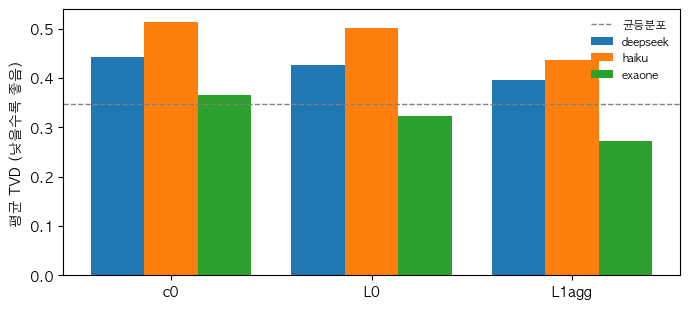

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.2))
w = 0.8 / M
for a, m in enumerate(MNAMES):
    ax.bar(np.arange(3) + a * w, TVD_L[a].mean(-1), w, label=m)
ax.axhline(TVD_UNIF.mean(), ls="--", c="gray", lw=1, label="균등분포")
ax.set_xticks(np.arange(3) + w * (M - 1) / 2, LEVELS); ax.set_ylabel("평균 TVD (낮을수록 좋음)")
ax.legend(frameon=False, fontsize=8); plt.tight_layout()

## 6. 한 줄의 효과: c0 → L0

In [10]:
d = TVD_L[:, 1] - TVD_L[:, 0]                            # [m, i]
ci = boot_ci(d)
line_effect = pd.DataFrame(dict(model=MNAMES, tvd_change=d.mean(-1), ci_lo=ci[0], ci_hi=ci[1],
    improved_share=(d < 0).mean(-1), shift_c0_L0=tvd(PR[:, 0], PR[:, 1]).mean(-1),
    mode_changed=(argmax_k(PR[:, 0]) != argmax_k(PR[:, 1])).mean(-1),
    refusal_c0=NREF[:, 0].sum(-1), refusal_L0=NREF[:, 1].sum(-1)))
line_effect

,model,tvd_change,ci_lo,ci_hi,improved_share,shift_c0_L0,mode_changed,refusal_c0,refusal_L0
0,deepseek,-0.017,-0.04,0.007,0.558,0.251,0.284,1,0
1,haiku,-0.014,-0.04,0.011,0.325,0.227,0.249,974,171
2,exaone,-0.043,-0.07,-0.017,0.614,0.293,0.340,0,1


## 7. 집단 구분 (L1 10셀)

In [11]:
HC, PRC, PSC = H[L1], PR[:, L1], PS[:, L1]               # [10,i,k], [m,10,i,k]
cell_tvd = tvd(PSC, HC)                                  # [m, 10, i]
popbase_tvd = tvd(HPOP, HC)                              # [10, i] 모집단 분포를 모든 셀에 쓸 때

# --- 쌍별 순위 (서열형·이진형, 평균 점수) ---
HM, HS = HMEAN[L1], HSE[L1]                              # [10, i]
MM = (PRC * CODES0).sum(-1)                              # [m, 10, i]
hd = HM[:, None] - HM[None, :]                           # [10, 10, i]
md_ = MM[:, :, None] - MM[:, None, :]                    # [m, 10, 10, i]
sig = np.abs(hd) > 2 * np.sqrt(HS[:, None] ** 2 + HS[None, :] ** 2)
upper = np.triu(np.ones((10, 10), bool), 1)[:, :, None]
validA = upper & ORD[None, None, :] & (hd != 0)          # [10, 10, i]
validB = validA & sig
score = np.where(np.sign(md_) == np.sign(hd), 1.0, np.where(md_ == 0, 0.5, 0.0))   # [m, 10, 10, i]
sex = cells.sex.to_numpy(); age = cells.age_band.to_numpy()
kind = np.where(age[:, None] == age[None, :], "sex", np.where(sex[:, None] == sex[None, :], "age", "both"))

def pair_stats(valid):
    out = {}
    for a, m in enumerate(MNAMES):
        s = np.where(valid, score[a], np.nan)
        item = np.nanmean(s.reshape(100, -1), 0)[ORD & valid.any((0, 1))]
        r = dict(pairs=int(valid.sum()), agree=np.nanmean(s), item_mean=item.mean(),
                 ci=np.round(boot_ci(item), 3).tolist(), model_tie=(md_[a] == 0)[valid].mean())
        for k in ["sex", "age", "both"]:
            r[f"agree_{k}"] = np.nanmean(np.where(valid & (kind[:, :, None] == k), score[a], np.nan))
        out[m] = r
    return pd.DataFrame(out).T

pairsA, pairsB = pair_stats(validA), pair_stats(validB)
display(pairsA.assign(rule="A"), pairsB.assign(rule="B"))

/var/folders/qn/2npgr5290ln20ss61v15vym80000gn/T/ipykernel_44136/354434998.py:22: RuntimeWarning: Mean of empty slice
  item = np.nanmean(s.reshape(100, -1), 0)[ORD & valid.any((0, 1))]
/var/folders/qn/2npgr5290ln20ss61v15vym80000gn/T/ipykernel_44136/354434998.py:22: RuntimeWarning: Mean of empty slice
  item = np.nanmean(s.reshape(100, -1), 0)[ORD & valid.any((0, 1))]


,pairs,agree,item_mean,ci,model_tie,agree_sex,agree_age,agree_both,rule
deepseek,8439,0.587,0.587,"[0.565, 0.609]",0.07,0.534,0.595,0.591,A
haiku,8439,0.547,0.547,"[0.531, 0.564]",0.428,0.52,0.552,0.549,A
exaone,8439,0.566,0.565,"[0.546, 0.585]",0.292,0.524,0.567,0.575,A


,pairs,agree,item_mean,ci,model_tie,agree_sex,agree_age,agree_both,rule
deepseek,1640,0.743,0.668,"[0.62, 0.715]",0.063,0.611,0.771,0.735,B
haiku,1640,0.646,0.596,"[0.556, 0.635]",0.335,0.587,0.655,0.646,B
exaone,1640,0.705,0.619,"[0.577, 0.661]",0.26,0.62,0.704,0.717,B


In [12]:
# --- 셀 간 퍼짐: 셀 평균의 표준편차 비와 상관 (문항별, 셀 축) ---
hz = HM - HM.mean(0); mz = MM - MM.mean(1, keepdims=True)
corr = (hz * mz).sum(1) / np.sqrt((hz ** 2).sum(0) * (mz ** 2).sum(1))    # [m, i]
corr = np.where(MM.std(1) > 0, corr, np.nan)
ratio = MM.std(1) / HM.std(0)

# --- 셀 안 보기 순위: 보기 쌍마다 순서가 사람과 같은가 ---
upk = np.triu(np.ones((K, K), bool), 1)
pairmask = upk & MASK[:, :, None] & MASK[:, None, :]                      # [i, k, k]
sh = np.sign(HC[..., :, None] - HC[..., None, :])                         # [10, i, k, k]
sb = np.sign(HPOP[:, :, None] - HPOP[:, None, :])                         # [i, k, k] 기준선
sm = np.sign(PRC[..., :, None] - PRC[..., None, :])                       # [m, 10, i, k, k]
vk = pairmask & (sh != 0)                                                 # [10, i, k, k]
def agree_rate(s):
    a = np.where(s == sh, 1.0, np.where(s == 0, 0.5, 0.0))
    num = (a * vk).sum((-1, -2)); den = vk.sum((-1, -2))
    return np.where(den > 0, num / np.maximum(den, 1), np.nan)            # [..., 10, i]
within_m = agree_rate(sm); within_b = agree_rate(sb)

L1_summary = pd.DataFrame(dict(model=MNAMES,
    cell_tvd=cell_tvd.mean((1, 2)), cell_tvd_popbase=popbase_tvd.mean(),
    pairA=pairsA.agree.to_numpy(), pairB=pairsB.agree.to_numpy(),
    spread_ratio_med=np.nanmedian(ratio[:, ORD], 1), spread_corr_med=np.nanmedian(corr[:, ORD], 1),
    corr_nan_share=np.isnan(corr[:, ORD]).mean(1),
    within_agree=np.nanmean(within_m, (1, 2)), within_base=np.nanmean(within_b)))
L1_summary.to_csv(OUT / "L1_summary.csv", index=False)
L1_summary

/var/folders/qn/2npgr5290ln20ss61v15vym80000gn/T/ipykernel_44136/460683350.py:3: RuntimeWarning: invalid value encountered in divide
  corr = (hz * mz).sum(1) / np.sqrt((hz ** 2).sum(0) * (mz ** 2).sum(1))    # [m, i]


,model,cell_tvd,cell_tvd_popbase,pairA,pairB,spread_ratio_med,spread_corr_med,corr_nan_share,within_agree,within_base
0,deepseek,0.436,0.08,0.587,0.743,1.159,0.271,0.011,0.727,0.943
1,haiku,0.501,0.08,0.547,0.646,1.037,0.182,0.255,0.676,0.943
2,exaone,0.321,0.08,0.566,0.705,1.845,0.180,0.043,0.719,0.943


## 8. 보정: T와 균등 혼합 λ를 calibration에서 고르고 validation에서 확인

In [13]:
Tb = T_GRID[:, None, None, None, None]                   # [T, 1, 1, 1, 1]
PT = to_prob(C[None], Tb)                                # [T, m, p, i, k]
TVD_T = tvd(by_level(PT.reshape(-1, P, I, K)).reshape(len(T_GRID), M, 3, I, K), HPOP)   # [T, m, 3, i]
cal, val = SPLIT == "calibration", SPLIT == "validation"
best_t = TVD_T[..., cal].mean(-1).argmin(0)              # [m, 3]

lam = LAM_GRID[:, None, None, None, None]
PL = (1 - lam) * PSL[None] + lam * UNIF                  # [λ, m, 3, i, k]
TVD_LAM = tvd(PL, HPOP)
best_l = TVD_LAM[..., cal].mean(-1).argmin(0)

rows = []
for a, m in enumerate(MNAMES):
    for l, lv in enumerate(LEVELS):
        t, q = best_t[a, l], best_l[a, l]
        rows.append(dict(model=m, level=lv, T=T_GRID[t], val_T1=TVD_L[a, l, val].mean(),
                         val_Tbest=TVD_T[t, a, l, val].mean(), lam=LAM_GRID[q], val_lam=TVD_LAM[q, a, l, val].mean(),
                         val_unif=TVD_UNIF[val].mean()))
calib = pd.DataFrame(rows); calib.to_csv(OUT / "calibration.csv", index=False)
calib

,model,level,T,val_T1,val_Tbest,lam,val_lam,val_unif
0,deepseek,c0,3.45,0.469,0.281,0.60,0.303,0.335
1,deepseek,L0,3.50,0.446,0.256,0.60,0.283,0.335
2,deepseek,L1agg,3.25,0.415,0.260,0.56,0.282,0.335
3,haiku,c0,4.75,0.524,0.298,0.70,0.301,0.335
4,haiku,L0,4.65,0.515,0.293,0.70,0.292,0.335
5,haiku,L1agg,4.00,0.429,0.254,0.62,0.261,0.335
6,exaone,c0,2.30,0.415,0.299,0.50,0.311,0.335
7,exaone,L0,2.10,0.355,0.267,0.44,0.279,0.335
8,exaone,L1agg,1.65,0.280,0.239,0.32,0.247,0.335


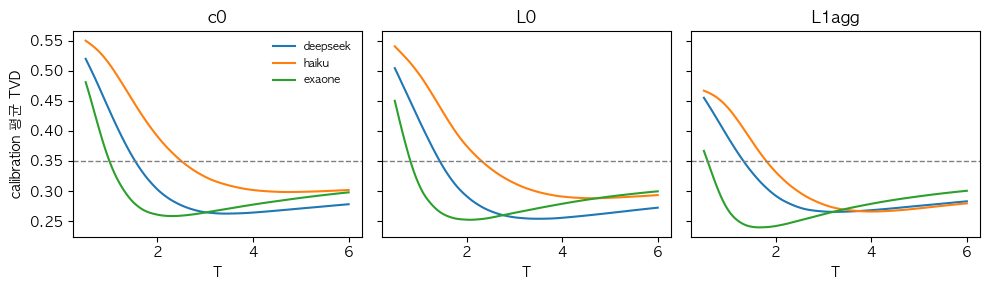

In [14]:
fig, axs = plt.subplots(1, 3, figsize=(10, 3), sharey=True)
for l, lv in enumerate(LEVELS):
    for a, m in enumerate(MNAMES):
        axs[l].plot(T_GRID, TVD_T[:, a, l][:, cal].mean(-1), label=m)
    axs[l].axhline(TVD_UNIF[cal].mean(), ls="--", c="gray", lw=1); axs[l].set_title(lv); axs[l].set_xlabel("T")
axs[0].set_ylabel("calibration 평균 TVD"); axs[0].legend(frameon=False, fontsize=8); plt.tight_layout()

## 9. 하위 집단 (L0, 보정 전 TVD)

In [15]:
item_df = man[["var", "split_60_20_20", "scale_type", "topic", "sensitivity_level"]].copy()
item_df["sens_bin"] = pd.cut(item_df.sensitivity_level, [-1, 1.5, 2.0, 9], labels=["<1.5", "1.5-2", ">=2"])
for a, m in enumerate(MNAMES):
    for l, lv in enumerate(LEVELS):
        item_df[f"{m}_{lv}"] = TVD_L[a, l]
item_df["unif"] = TVD_UNIF
item_df.to_csv(OUT / "item_level.csv", index=False)
cols = [f"{m}_L0" for m in MNAMES] + ["unif"]
for g in ["topic", "scale_type", "sens_bin"]:
    t = item_df.groupby(g, observed=True)[cols].mean(); t["n"] = item_df.groupby(g, observed=True).size()
    display(t.sort_values("n", ascending=False))

,deepseek_L0,haiku_L0,exaone_L0,unif,n
topic,,,,,
social_trust_participation,0.371,0.489,0.298,0.350,59
politics_gov,0.489,0.510,0.309,0.328,38
health_wellbeing,0.440,0.499,0.373,0.379,26
migration_identity,0.552,0.525,0.345,0.345,22
economy_work_welfare,0.333,0.489,0.346,0.366,19
personal_fact,0.243,0.371,0.225,0.372,12
religion_values,0.451,0.591,0.257,0.316,10
family_gender,0.567,0.459,0.454,0.270,5
media_information,0.500,0.605,0.458,0.296,5


,deepseek_L0,haiku_L0,exaone_L0,unif,n
scale_type,,,,,
ordinal_monotone,0.446,0.519,0.338,0.357,169
binary,0.256,0.390,0.186,0.255,19
nominal_unordered,0.380,0.364,0.309,0.377,8
frequency_nonmonotone_code,0.561,0.568,0.355,0.210,1


,deepseek_L0,haiku_L0,exaone_L0,unif,n
sens_bin,,,,,
1.5-2,0.419,0.500,0.334,0.353,104
<1.5,0.415,0.509,0.287,0.336,71
>=2,0.496,0.472,0.385,0.355,22
